<a href="https://colab.research.google.com/github/TangenAiden/MIS433/blob/main/Churn_aiden_tangen.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [289]:
import kagglehub
kagglehub.login()

In [290]:
import kagglehub

# Download latest version
path = kagglehub.competition_download('mis-433-fall-2026-churn')

print("Path to competition files:", path)

Path to competition files: /root/.cache/kagglehub/competitions/mis-433-fall-2026-churn


In [291]:
import os
print(os.listdir(path))

['churn_train.csv', 'demographics.csv', 'churn_test.csv', 'accounts.csv', 'sample_submission.csv', 'services.csv']


In [292]:
import pandas as pd
import numpy as np

In [293]:
churn_train = pd.read_csv(os.path.join(path,'churn_train.csv'))
churn_train

,CustomerNo,Churn
0,1201,0
1,1202,0
2,1205,1
3,1206,0
4,1207,0
...,...,...
4233,6492,0
4234,6493,0
4235,6494,0
4236,6497,0


In [294]:
accounts = pd.read_csv(os.path.join(path,'accounts.csv'))
accounts

,CustomerNo,BaseCharges,DOC,TotalCharges,DOE,ElectronicBilling,ContractType,PaymentMethod
0,1201,478.50,5-1-2012,5920.00,10-Jan-11,No,One year,Electronic check
1,1202,103.25,5-1-2012,103.25,6-Dec-11,No,Month-to-month,Electronic check
2,1203,399.75,5-1-2012,5217.00,10-Jan-11,Yes,Month-to-month,Bank transfer (automatic)
3,1204,324.75,5-1-2012,22757.50,6-Apr-06,No,One year,Bank transfer (automatic)
4,1205,372.50,5-1-2012,372.50,6-Dec-11,Yes,Month-to-month,Electronic check
...,...,...,...,...,...,...,...,...
5293,6494,99.50,5-1-2012,5113.00,27-Dec-07,Yes,Two year,Credit card (automatic)
5294,6495,471.00,5-1-2012,29477.25,1-Jan-07,Yes,Month-to-month,Credit card (automatic)
5295,6496,347.50,5-1-2012,8260.50,14-Feb-10,Yes,Month-to-month,Credit card (automatic)
5296,6497,426.00,5-1-2012,14372.25,21-Mar-09,Yes,Month-to-month,Credit card (automatic)


In [295]:
churn_test = pd.read_csv(os.path.join(path,'churn_test.csv'))
churn_test

,CustomerNo
0,1203
1,1204
2,1208
3,1220
4,1221
...,...
1055,6478
1056,6486
1057,6487
1058,6495


In [296]:
sample_submission = pd.read_csv(os.path.join(path,'sample_submission.csv'))
sample_submission

,CustomerNo,Churn
0,1203,0
1,1204,0
2,1208,0
3,1220,0
4,1221,0
...,...,...
1055,6478,0
1056,6486,0
1057,6487,0
1058,6495,0


In [297]:
services = pd.read_csv(os.path.join(path,'services.csv'))
services

,CustomerNo,TypeOfService,SeviceDetails
0,1201,DeviceProtection,Yes
1,1201,HasPhoneService,1
2,1201,InternetServiceCategory,Fiber optic
3,1201,MultipleLines,No
4,1201,OnlineBackup,No
...,...,...,...
47677,6498,OnlineBackup,No internet service
47678,6498,OnlineSecurity,No internet service
47679,6498,StreamingMovies,No internet service
47680,6498,StreamingTelevision,No internet service


In [298]:
demographics = pd.read_csv(os.path.join(path,'demographics.csv'))
demographics

,CustomerNo,Country,State,Retired,HasPartner,HasDependents,Education,Gender
0,1201,India,Maharashtra,0,2,2,Masters,Male
1,1202,India,Maharashtra,0,2,2,ProfessionalQalification,Male
2,1203,India,Maharashtra,0,2,2,ProfessionalQalification,Male
3,1204,India,Maharashtra,0,2,1,ProfessionalQalification,Male
4,1205,India,Maharashtra,0,2,2,ProfessionalQalification,Female
...,...,...,...,...,...,...,...,...
5293,6494,India,Maharashtra,0,2,2,ProfessionalQalification,Male
5294,6495,India,Maharashtra,1,1,2,ProfessionalQalification,Female
5295,6496,India,Maharashtra,0,1,1,Masters,Female
5296,6497,India,Maharashtra,1,1,2,Highschool or below,Male


Here is what I've gathered with the beginning of this churn assignment:
      
      **churn_train** is the file of data I need to use to train for the test data
      **churn_test** is the testing data for when I am finished with my model
      **sample_submission** is an example of the results
      **demographics** is a data set of the customer demographics
      **accounts** is a data set of every account
      **services** is a data set of the services provided by the company


In [299]:
services.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 47682 entries, 0 to 47681
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   CustomerNo     47682 non-null  int64 
 1   TypeOfService  47682 non-null  object
 2   SeviceDetails  47682 non-null  object
dtypes: int64(1), object(2)
memory usage: 1.1+ MB


In [300]:
print(services["TypeOfService"].unique())

['DeviceProtection' 'HasPhoneService' 'InternetServiceCategory'
 'MultipleLines' 'OnlineBackup' 'OnlineSecurity' 'StreamingMovies'
 'StreamingTelevision' 'TechnicalSupport']


Above are the types of service that the company offers, this is good to know.

In [301]:
print(accounts.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5298 entries, 0 to 5297
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerNo         5298 non-null   int64  
 1   BaseCharges        5298 non-null   float64
 2   DOC                5298 non-null   object 
 3   TotalCharges       5288 non-null   float64
 4   DOE                5298 non-null   object 
 5   ElectronicBilling  5298 non-null   object 
 6   ContractType       5293 non-null   object 
 7   PaymentMethod      5298 non-null   object 
dtypes: float64(2), int64(1), object(5)
memory usage: 331.3+ KB
None


Here is all the account information, no need to go in depth until further on down.

Questions I have for now. What is the end goal of this churn assignment? How will I get there? What are some different perspectives I can take on how to build my models? I hope to have these answered by the end of the assignment.

In [302]:
accounts.isnull().sum()

,0
CustomerNo,0
BaseCharges,0
DOC,0
TotalCharges,10
DOE,0
ElectronicBilling,0
ContractType,5
PaymentMethod,0


I wanted to look for null data because the first step I wanted to take was to clean up the data. So here for the accounts df we have 10 null Total Charges and 5 Null ContractTypes. I will identify these rows and have them removed from the data.

In [303]:
services.isnull().sum()

,0
CustomerNo,0
TypeOfService,0
SeviceDetails,0


No null data in services

In [304]:
churn_train.isnull().sum()

,0
CustomerNo,0
Churn,0


None here, although I feel that was the obvious case.

In [305]:
demographics.isnull().sum()

,0
CustomerNo,0
Country,0
State,0
Retired,0
HasPartner,0
HasDependents,0
Education,10
Gender,4


And we have 10 for education and 4 for gender

I have decided to merge the four data sets, so that I can take a look at all of the null values and decide what to do with them.

In [306]:
churnconnect =(
    churn_train
    .merge(services,on=['CustomerNo'],how='left')
    .merge(demographics,on=['CustomerNo'],how='left')
    .merge(accounts, on=['CustomerNo'],how='left')
)

In [307]:
churnconnect

,CustomerNo,Churn,TypeOfService,SeviceDetails,Country,State,Retired,HasPartner,HasDependents,Education,Gender,BaseCharges,DOC,TotalCharges,DOE,ElectronicBilling,ContractType,PaymentMethod
0,1201,0,DeviceProtection,Yes,India,Maharashtra,0,2,2,Masters,Male,478.50,5-1-2012,5920.0,10-Jan-11,No,One year,Electronic check
1,1201,0,HasPhoneService,1,India,Maharashtra,0,2,2,Masters,Male,478.50,5-1-2012,5920.0,10-Jan-11,No,One year,Electronic check
2,1201,0,InternetServiceCategory,Fiber optic,India,Maharashtra,0,2,2,Masters,Male,478.50,5-1-2012,5920.0,10-Jan-11,No,One year,Electronic check
3,1201,0,MultipleLines,No,India,Maharashtra,0,2,2,Masters,Male,478.50,5-1-2012,5920.0,10-Jan-11,No,One year,Electronic check
4,1201,0,OnlineBackup,No,India,Maharashtra,0,2,2,Masters,Male,478.50,5-1-2012,5920.0,10-Jan-11,No,One year,Electronic check
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
38137,6498,1,OnlineBackup,No internet service,India,Maharashtra,0,1,2,Highschool or below,Female,97.25,5-1-2012,6043.0,3-Oct-06,No,Two year,Credit card (automatic)
38138,6498,1,OnlineSecurity,No internet service,India,Maharashtra,0,1,2,Highschool or below,Female,97.25,5-1-2012,6043.0,3-Oct-06,No,Two year,Credit card (automatic)
38139,6498,1,StreamingMovies,No internet service,India,Maharashtra,0,1,2,Highschool or below,Female,97.25,5-1-2012,6043.0,3-Oct-06,No,Two year,Credit card (automatic)
38140,6498,1,StreamingTelevision,No internet service,India,Maharashtra,0,1,2,Highschool or below,Female,97.25,5-1-2012,6043.0,3-Oct-06,No,Two year,Credit card (automatic)


Now that everything is together, I can look at how I want to organize it, do the variables make sense? how can I look at the null rows?

In [308]:
#Trying to find which rows are null so that I can return and view
nulldfG = churnconnect.loc[churnconnect.Gender.isnull(),['CustomerNo']].assign(Genderisnull='Gender')

In [309]:
nulldfE = churnconnect.loc[churnconnect.Education.isnull(),['CustomerNo']].assign(Educationisnull='Education')
nulldfE

,CustomerNo,Educationisnull
5148,1888,Education
5149,1888,Education
5150,1888,Education
5151,1888,Education
5152,1888,Education
...,...,...
35860,6180,Education
35861,6180,Education
35862,6180,Education
35863,6180,Education


In [310]:
nulldfCT = churnconnect.loc[churnconnect.ContractType.isnull(),['CustomerNo']].assign(ContractTypeisnull='ContractType')

In [311]:
nulldfTC = churnconnect.loc[churnconnect.TotalCharges.isnull(),['CustomerNo']].assign(TotalChargesisnull='TotalCharges')

In [312]:
allnulldf = (
    nulldfG
    .merge(nulldfE,on='CustomerNo',how='outer')
    .merge(nulldfCT,on='CustomerNo',how='outer')
    .merge(nulldfTC,on='CustomerNo',how='outer')
    .fillna('-')
    .drop_duplicates()
    .reset_index()
)
allnulldf

,index,CustomerNo,Genderisnull,Educationisnull,ContractTypeisnull,TotalChargesisnull
0,0,1704,-,-,-,TotalCharges
1,9,1841,-,-,ContractType,-
2,18,1883,-,-,-,TotalCharges
3,27,1888,-,Education,-,-
4,36,2080,-,Education,-,-
5,45,2159,-,Education,-,-
6,54,2339,-,Education,-,-
7,63,2362,Gender,-,-,-
8,72,2442,-,Education,-,-
9,81,2697,-,-,-,TotalCharges


There are a lot of duplicates so I want to check really quickly

What is happening right now is really messy, but it all came together. i was able to extract the individual rows and customers that had a null value. That was my end goal for this so far. I also realized that when I merged the everything into churnconnect, it created multiple different rows for the same customer number. I was able to drop the duplicates and find the customers. Also, while sleuthing through the churnconnect df, I noted that the reason it has multiple different rows is due to the typeofservice column. I plan on moving them into multple different columns.

In [313]:
services_all = services.pivot(index='CustomerNo', columns='TypeOfService', values='SeviceDetails').reset_index()
services_all.columns.name = None

In [314]:
#new churnconnect
churnconnect =(
    churn_train
    .merge(services_all,on=['CustomerNo'],how='left')
    .merge(demographics,on=['CustomerNo'],how='left')
    .merge(accounts, on=['CustomerNo'],how='left')
)
churnconnect

,CustomerNo,Churn,DeviceProtection,HasPhoneService,InternetServiceCategory,MultipleLines,OnlineBackup,OnlineSecurity,StreamingMovies,StreamingTelevision,...,HasDependents,Education,Gender,BaseCharges,DOC,TotalCharges,DOE,ElectronicBilling,ContractType,PaymentMethod
0,1201,0,Yes,1,Fiber optic,No,No,No,Yes,Yes,...,2,Masters,Male,478.50,5-1-2012,5920.00,10-Jan-11,No,One year,Electronic check
1,1202,0,No internet service,1,No,No,No internet service,No internet service,No internet service,No internet service,...,2,ProfessionalQalification,Male,103.25,5-1-2012,103.25,6-Dec-11,No,Month-to-month,Electronic check
2,1205,1,No,1,Fiber optic,Yes,No,No,No,No,...,2,ProfessionalQalification,Female,372.50,5-1-2012,372.50,6-Dec-11,Yes,Month-to-month,Electronic check
3,1206,0,No internet service,1,No,No,No internet service,No internet service,No internet service,No internet service,...,2,Highschool or below,Male,99.50,5-1-2012,6775.50,7-Mar-06,Yes,Two year,Credit card (automatic)
4,1207,0,No internet service,1,No,No,No internet service,No internet service,No internet service,No internet service,...,2,Graduation,Male,91.25,5-1-2012,2673.50,17-Sep-09,No,One year,Credit card (automatic)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4233,6492,0,No internet service,1,No,No,No internet service,No internet service,No internet service,No internet service,...,2,Masters,Male,100.00,5-1-2012,6980.00,5-Jun-06,Yes,Two year,Credit card (automatic)
4234,6493,0,Yes,0,DSL,No phone service,Yes,No,Yes,No,...,1,Masters,Female,227.75,5-1-2012,10541.75,26-Jan-08,No,Month-to-month,Credit card (automatic)
4235,6494,0,No internet service,1,No,No,No internet service,No internet service,No internet service,No internet service,...,2,ProfessionalQalification,Male,99.50,5-1-2012,5113.00,27-Dec-07,Yes,Two year,Credit card (automatic)
4236,6497,0,Yes,1,Fiber optic,No,No,No,No,Yes,...,2,Highschool or below,Male,426.00,5-1-2012,14372.25,21-Mar-09,Yes,Month-to-month,Credit card (automatic)


Now I can get to either removing the null data, changing the value dtype, or using something like mean to fill them in automatically

First, I will be trying to understand the value dtype

In [315]:
churnconnect['HasPhoneService'].value_counts()

#it seems there are only two types of has phone service. This tells me that its done with binary.
#I can change this to a String Yes or No.

,count
HasPhoneService,
1,3818
0,420


In [316]:
churnconnect['HasPhoneService'] = churnconnect['HasPhoneService'].replace({'1':'Yes','0':'No'})

In [317]:
churnconnect
#the HasPhoneService Column was a string coincidentally, it is now yes or no, a more readable and matching value

,CustomerNo,Churn,DeviceProtection,HasPhoneService,InternetServiceCategory,MultipleLines,OnlineBackup,OnlineSecurity,StreamingMovies,StreamingTelevision,...,HasDependents,Education,Gender,BaseCharges,DOC,TotalCharges,DOE,ElectronicBilling,ContractType,PaymentMethod
0,1201,0,Yes,Yes,Fiber optic,No,No,No,Yes,Yes,...,2,Masters,Male,478.50,5-1-2012,5920.00,10-Jan-11,No,One year,Electronic check
1,1202,0,No internet service,Yes,No,No,No internet service,No internet service,No internet service,No internet service,...,2,ProfessionalQalification,Male,103.25,5-1-2012,103.25,6-Dec-11,No,Month-to-month,Electronic check
2,1205,1,No,Yes,Fiber optic,Yes,No,No,No,No,...,2,ProfessionalQalification,Female,372.50,5-1-2012,372.50,6-Dec-11,Yes,Month-to-month,Electronic check
3,1206,0,No internet service,Yes,No,No,No internet service,No internet service,No internet service,No internet service,...,2,Highschool or below,Male,99.50,5-1-2012,6775.50,7-Mar-06,Yes,Two year,Credit card (automatic)
4,1207,0,No internet service,Yes,No,No,No internet service,No internet service,No internet service,No internet service,...,2,Graduation,Male,91.25,5-1-2012,2673.50,17-Sep-09,No,One year,Credit card (automatic)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4233,6492,0,No internet service,Yes,No,No,No internet service,No internet service,No internet service,No internet service,...,2,Masters,Male,100.00,5-1-2012,6980.00,5-Jun-06,Yes,Two year,Credit card (automatic)
4234,6493,0,Yes,No,DSL,No phone service,Yes,No,Yes,No,...,1,Masters,Female,227.75,5-1-2012,10541.75,26-Jan-08,No,Month-to-month,Credit card (automatic)
4235,6494,0,No internet service,Yes,No,No,No internet service,No internet service,No internet service,No internet service,...,2,ProfessionalQalification,Male,99.50,5-1-2012,5113.00,27-Dec-07,Yes,Two year,Credit card (automatic)
4236,6497,0,Yes,Yes,Fiber optic,No,No,No,No,Yes,...,2,Highschool or below,Male,426.00,5-1-2012,14372.25,21-Mar-09,Yes,Month-to-month,Credit card (automatic)


In [318]:
churnconnect.ContractType.value_counts()

,count
ContractType,
Month-to-month,2235
Two year,1081
One year,919


Only 3, workable

In [319]:
churnconnect.HasDependents.value_counts()

,count
HasDependents,
2,2937
1,1301


It seems that 1 and 2 are code for yes and no. I will change it to 1:"No" and 2:"Yes"

In [320]:
churnconnect['HasDependents'] = churnconnect['HasDependents'].replace({1:'No',2:'Yes'})
churnconnect

,CustomerNo,Churn,DeviceProtection,HasPhoneService,InternetServiceCategory,MultipleLines,OnlineBackup,OnlineSecurity,StreamingMovies,StreamingTelevision,...,HasDependents,Education,Gender,BaseCharges,DOC,TotalCharges,DOE,ElectronicBilling,ContractType,PaymentMethod
0,1201,0,Yes,Yes,Fiber optic,No,No,No,Yes,Yes,...,Yes,Masters,Male,478.50,5-1-2012,5920.00,10-Jan-11,No,One year,Electronic check
1,1202,0,No internet service,Yes,No,No,No internet service,No internet service,No internet service,No internet service,...,Yes,ProfessionalQalification,Male,103.25,5-1-2012,103.25,6-Dec-11,No,Month-to-month,Electronic check
2,1205,1,No,Yes,Fiber optic,Yes,No,No,No,No,...,Yes,ProfessionalQalification,Female,372.50,5-1-2012,372.50,6-Dec-11,Yes,Month-to-month,Electronic check
3,1206,0,No internet service,Yes,No,No,No internet service,No internet service,No internet service,No internet service,...,Yes,Highschool or below,Male,99.50,5-1-2012,6775.50,7-Mar-06,Yes,Two year,Credit card (automatic)
4,1207,0,No internet service,Yes,No,No,No internet service,No internet service,No internet service,No internet service,...,Yes,Graduation,Male,91.25,5-1-2012,2673.50,17-Sep-09,No,One year,Credit card (automatic)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4233,6492,0,No internet service,Yes,No,No,No internet service,No internet service,No internet service,No internet service,...,Yes,Masters,Male,100.00,5-1-2012,6980.00,5-Jun-06,Yes,Two year,Credit card (automatic)
4234,6493,0,Yes,No,DSL,No phone service,Yes,No,Yes,No,...,No,Masters,Female,227.75,5-1-2012,10541.75,26-Jan-08,No,Month-to-month,Credit card (automatic)
4235,6494,0,No internet service,Yes,No,No,No internet service,No internet service,No internet service,No internet service,...,Yes,ProfessionalQalification,Male,99.50,5-1-2012,5113.00,27-Dec-07,Yes,Two year,Credit card (automatic)
4236,6497,0,Yes,Yes,Fiber optic,No,No,No,No,Yes,...,Yes,Highschool or below,Male,426.00,5-1-2012,14372.25,21-Mar-09,Yes,Month-to-month,Credit card (automatic)


In [321]:
print(churnconnect.DOC.dtype)
print(churnconnect.DOE.dtype)

object
object


These need to be changed to actual dates. Then I can find the length of time.

In [322]:
churnconnect['DOC'] = pd.to_datetime(churnconnect['DOC'],format='%m-%d-%Y',errors='coerce')
churnconnect['DOE'] = pd.to_datetime(churnconnect['DOE'], format='%d-%b-%y', errors='coerce')
churnconnect

,CustomerNo,Churn,DeviceProtection,HasPhoneService,InternetServiceCategory,MultipleLines,OnlineBackup,OnlineSecurity,StreamingMovies,StreamingTelevision,...,HasDependents,Education,Gender,BaseCharges,DOC,TotalCharges,DOE,ElectronicBilling,ContractType,PaymentMethod
0,1201,0,Yes,Yes,Fiber optic,No,No,No,Yes,Yes,...,Yes,Masters,Male,478.50,2012-05-01,5920.00,2011-01-10,No,One year,Electronic check
1,1202,0,No internet service,Yes,No,No,No internet service,No internet service,No internet service,No internet service,...,Yes,ProfessionalQalification,Male,103.25,2012-05-01,103.25,2011-12-06,No,Month-to-month,Electronic check
2,1205,1,No,Yes,Fiber optic,Yes,No,No,No,No,...,Yes,ProfessionalQalification,Female,372.50,2012-05-01,372.50,2011-12-06,Yes,Month-to-month,Electronic check
3,1206,0,No internet service,Yes,No,No,No internet service,No internet service,No internet service,No internet service,...,Yes,Highschool or below,Male,99.50,2012-05-01,6775.50,2006-03-07,Yes,Two year,Credit card (automatic)
4,1207,0,No internet service,Yes,No,No,No internet service,No internet service,No internet service,No internet service,...,Yes,Graduation,Male,91.25,2012-05-01,2673.50,2009-09-17,No,One year,Credit card (automatic)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4233,6492,0,No internet service,Yes,No,No,No internet service,No internet service,No internet service,No internet service,...,Yes,Masters,Male,100.00,2012-05-01,6980.00,2006-06-05,Yes,Two year,Credit card (automatic)
4234,6493,0,Yes,No,DSL,No phone service,Yes,No,Yes,No,...,No,Masters,Female,227.75,2012-05-01,10541.75,2008-01-26,No,Month-to-month,Credit card (automatic)
4235,6494,0,No internet service,Yes,No,No,No internet service,No internet service,No internet service,No internet service,...,Yes,ProfessionalQalification,Male,99.50,2012-05-01,5113.00,2007-12-27,Yes,Two year,Credit card (automatic)
4236,6497,0,Yes,Yes,Fiber optic,No,No,No,No,Yes,...,Yes,Highschool or below,Male,426.00,2012-05-01,14372.25,2009-03-21,Yes,Month-to-month,Credit card (automatic)


From what I've seen, DOE is the date of entry and DOC is probably when its either churned or payment is collected. It is more likely to be when the last payment was collected. I want to find the length that the customer has been subscribed.

In [323]:
churnconnect['Lengthmonths'] = (churnconnect['DOC'] - churnconnect['DOE']).dt.days/30
churnconnect['Lengthmonths'] = np.floor(churnconnect['Lengthmonths'])
churnconnect

,CustomerNo,Churn,DeviceProtection,HasPhoneService,InternetServiceCategory,MultipleLines,OnlineBackup,OnlineSecurity,StreamingMovies,StreamingTelevision,...,Education,Gender,BaseCharges,DOC,TotalCharges,DOE,ElectronicBilling,ContractType,PaymentMethod,Lengthmonths
0,1201,0,Yes,Yes,Fiber optic,No,No,No,Yes,Yes,...,Masters,Male,478.50,2012-05-01,5920.00,2011-01-10,No,One year,Electronic check,15.0
1,1202,0,No internet service,Yes,No,No,No internet service,No internet service,No internet service,No internet service,...,ProfessionalQalification,Male,103.25,2012-05-01,103.25,2011-12-06,No,Month-to-month,Electronic check,4.0
2,1205,1,No,Yes,Fiber optic,Yes,No,No,No,No,...,ProfessionalQalification,Female,372.50,2012-05-01,372.50,2011-12-06,Yes,Month-to-month,Electronic check,4.0
3,1206,0,No internet service,Yes,No,No,No internet service,No internet service,No internet service,No internet service,...,Highschool or below,Male,99.50,2012-05-01,6775.50,2006-03-07,Yes,Two year,Credit card (automatic),74.0
4,1207,0,No internet service,Yes,No,No,No internet service,No internet service,No internet service,No internet service,...,Graduation,Male,91.25,2012-05-01,2673.50,2009-09-17,No,One year,Credit card (automatic),31.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4233,6492,0,No internet service,Yes,No,No,No internet service,No internet service,No internet service,No internet service,...,Masters,Male,100.00,2012-05-01,6980.00,2006-06-05,Yes,Two year,Credit card (automatic),71.0
4234,6493,0,Yes,No,DSL,No phone service,Yes,No,Yes,No,...,Masters,Female,227.75,2012-05-01,10541.75,2008-01-26,No,Month-to-month,Credit card (automatic),51.0
4235,6494,0,No internet service,Yes,No,No,No internet service,No internet service,No internet service,No internet service,...,ProfessionalQalification,Male,99.50,2012-05-01,5113.00,2007-12-27,Yes,Two year,Credit card (automatic),52.0
4236,6497,0,Yes,Yes,Fiber optic,No,No,No,No,Yes,...,Highschool or below,Male,426.00,2012-05-01,14372.25,2009-03-21,Yes,Month-to-month,Credit card (automatic),37.0


This is definitely cleaner now that I can see the timeline and length. However, I am a little skeptical of the basecharges. I am going to do some math to see if its monthly or not.

In [324]:
testa = int(52)
testb = int(99.50)
pr = testa*testb
print(pr)

5148


Seems like its done on a monthly basis, so that makes more sense and is fine. I am going to fill the Null values for total charges using the months and base pay.

In [325]:
allnulldf.loc[allnulldf.TotalChargesisnull == "TotalCharges",['CustomerNo']].reset_index()

,index,CustomerNo
0,0,1704
1,2,1883
2,9,2697
3,11,3245
4,12,3377
5,13,4067
6,15,4279
7,16,4466


I have the CustomerNo of the null items with no charges, now I am going to pull their base charges and length and replace the null

In [326]:
churnconnect.loc[churnconnect['CustomerNo'] == 1704, 'TotalCharges'] = churnconnect['BaseCharges'] * churnconnect['Lengthmonths']
churnconnect.loc[churnconnect['CustomerNo'] == 1704]

,CustomerNo,Churn,DeviceProtection,HasPhoneService,InternetServiceCategory,MultipleLines,OnlineBackup,OnlineSecurity,StreamingMovies,StreamingTelevision,...,Education,Gender,BaseCharges,DOC,TotalCharges,DOE,ElectronicBilling,ContractType,PaymentMethod,Lengthmonths
413,1704,0,No internet service,Yes,No,No,No internet service,No internet service,No internet service,No internet service,...,Graduation,Male,98.5,2012-05-01,295.5,2012-01-05,Yes,One year,Mailed check,3.0


Went back and rounded down the months because it made no sense to pay for a partial month you wouldn't have actually paid for yet.

In [327]:
churnconnect.loc[churnconnect['CustomerNo'] == 1883, 'TotalCharges'] = churnconnect['BaseCharges'] * churnconnect['Lengthmonths']
churnconnect.loc[churnconnect['CustomerNo'] == 2697, 'TotalCharges'] = churnconnect['BaseCharges'] * churnconnect['Lengthmonths']
churnconnect.loc[churnconnect['CustomerNo'] == 3245, 'TotalCharges'] = churnconnect['BaseCharges'] * churnconnect['Lengthmonths']
churnconnect.loc[churnconnect['CustomerNo'] == 3377, 'TotalCharges'] = churnconnect['BaseCharges'] * churnconnect['Lengthmonths']
churnconnect.loc[churnconnect['CustomerNo'] == 4067, 'TotalCharges'] = churnconnect['BaseCharges'] * churnconnect['Lengthmonths']
churnconnect.loc[churnconnect['CustomerNo'] == 4279, 'TotalCharges'] = churnconnect['BaseCharges'] * churnconnect['Lengthmonths']
churnconnect.loc[churnconnect['CustomerNo'] == 4466, 'TotalCharges'] = churnconnect['BaseCharges'] * churnconnect['Lengthmonths']
churnconnect

,CustomerNo,Churn,DeviceProtection,HasPhoneService,InternetServiceCategory,MultipleLines,OnlineBackup,OnlineSecurity,StreamingMovies,StreamingTelevision,...,Education,Gender,BaseCharges,DOC,TotalCharges,DOE,ElectronicBilling,ContractType,PaymentMethod,Lengthmonths
0,1201,0,Yes,Yes,Fiber optic,No,No,No,Yes,Yes,...,Masters,Male,478.50,2012-05-01,5920.00,2011-01-10,No,One year,Electronic check,15.0
1,1202,0,No internet service,Yes,No,No,No internet service,No internet service,No internet service,No internet service,...,ProfessionalQalification,Male,103.25,2012-05-01,103.25,2011-12-06,No,Month-to-month,Electronic check,4.0
2,1205,1,No,Yes,Fiber optic,Yes,No,No,No,No,...,ProfessionalQalification,Female,372.50,2012-05-01,372.50,2011-12-06,Yes,Month-to-month,Electronic check,4.0
3,1206,0,No internet service,Yes,No,No,No internet service,No internet service,No internet service,No internet service,...,Highschool or below,Male,99.50,2012-05-01,6775.50,2006-03-07,Yes,Two year,Credit card (automatic),74.0
4,1207,0,No internet service,Yes,No,No,No internet service,No internet service,No internet service,No internet service,...,Graduation,Male,91.25,2012-05-01,2673.50,2009-09-17,No,One year,Credit card (automatic),31.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4233,6492,0,No internet service,Yes,No,No,No internet service,No internet service,No internet service,No internet service,...,Masters,Male,100.00,2012-05-01,6980.00,2006-06-05,Yes,Two year,Credit card (automatic),71.0
4234,6493,0,Yes,No,DSL,No phone service,Yes,No,Yes,No,...,Masters,Female,227.75,2012-05-01,10541.75,2008-01-26,No,Month-to-month,Credit card (automatic),51.0
4235,6494,0,No internet service,Yes,No,No,No internet service,No internet service,No internet service,No internet service,...,ProfessionalQalification,Male,99.50,2012-05-01,5113.00,2007-12-27,Yes,Two year,Credit card (automatic),52.0
4236,6497,0,Yes,Yes,Fiber optic,No,No,No,No,Yes,...,Highschool or below,Male,426.00,2012-05-01,14372.25,2009-03-21,Yes,Month-to-month,Credit card (automatic),37.0


In [328]:
churnconnect.TotalCharges.isnull().sum()

np.int64(0)

I fixed the Total Charges column. It is important to note that this is hypothetical as it doesn't account for discounts, free months, and other cost lowering deals.

Next step is looking at gender. I think what I want to do is try and find the shared columns and values and use whatever gender has the most. this is my way of thinking out loud I am not sure if what I am trying to say is making sense. I think mode might be the play here.

In [329]:
gender_newvalue = churnconnect['Gender'].mode()[0]
print(gender_newvalue)

Male


Seems male is the most common, so I will use that.

In [330]:
churnconnect['Gender'] = churnconnect['Gender'].fillna(gender_newvalue)

looking back at my program, I realize that there is a likelihood that the test data has the other null values. I will have to go back and check before I fully run the model.

In [331]:
churnconnect.isnull().sum()

,0
CustomerNo,0
Churn,0
DeviceProtection,0
HasPhoneService,0
InternetServiceCategory,0
MultipleLines,0
OnlineBackup,0
OnlineSecurity,0
StreamingMovies,0
StreamingTelevision,0


Next is contract type

Im thinking I should also use mode for it since there are only 3 null values

In [332]:
contracttype_newvalue = churnconnect['ContractType'].mode()[0]
print(contracttype_newvalue)

Month-to-month


In [333]:
churnconnect['ContractType'] = churnconnect['ContractType'].fillna(contracttype_newvalue)

In [334]:
churnconnect.isnull().sum()

,0
CustomerNo,0
Churn,0
DeviceProtection,0
HasPhoneService,0
InternetServiceCategory,0
MultipleLines,0
OnlineBackup,0
OnlineSecurity,0
StreamingMovies,0
StreamingTelevision,0


Professional Qualification is spelled wrong so I need to fix that.

In [335]:
for i in [churnconnect]:
    i['Education'] = i['Education'].replace('ProfessionalQalification', 'ProfessionalQualification')

I am going to go mode for this too. It is the easiest option. If my model shows poor performance I can come back to it.

In [336]:
education_newvalue = churnconnect['Education'].mode()[0]
print(education_newvalue)

Highschool or below


In [337]:
churnconnect['Education'] = churnconnect['Education'].fillna(education_newvalue)

In [338]:
churnconnect.isnull().sum()

,0
CustomerNo,0
Churn,0
DeviceProtection,0
HasPhoneService,0
InternetServiceCategory,0
MultipleLines,0
OnlineBackup,0
OnlineSecurity,0
StreamingMovies,0
StreamingTelevision,0


This shows no null values left in the merged training data, will check for them in the test data

In [339]:
churn_test.isnull().sum()

,0
CustomerNo,0


So there is no null values in the test data, which is good.

In [340]:
testconnect = (
    churn_test
    .merge(services_all, on='CustomerNo', how='left')
    .merge(demographics, on='CustomerNo', how='left')
    .merge(accounts, on='CustomerNo', how='left')
)

testconnect.isnull().sum()

,0
CustomerNo,0
DeviceProtection,0
HasPhoneService,0
InternetServiceCategory,0
MultipleLines,0
OnlineBackup,0
OnlineSecurity,0
StreamingMovies,0
StreamingTelevision,0
TechnicalSupport,0


So what I believe what the test data with the merged values is showing is that there are null values in the test customers show. I will do the same procedure as the last few in churnconnect

In [341]:
education_newvalue1 = testconnect['Education'].mode()[0]
print(education_newvalue1)

Highschool or below


In [342]:
testconnect['Education'] = testconnect['Education'].fillna(education_newvalue1)

In [343]:
contracttype_newvalue1 = testconnect['ContractType'].mode()[0]
print(contracttype_newvalue1)

Month-to-month


In [344]:
testconnect['ContractType'] = testconnect['ContractType'].fillna(contracttype_newvalue1)

In [345]:
gender_newvalue1 = testconnect['Gender'].mode()[0]
print(gender_newvalue1)

Female


In [346]:
testconnect['Gender'] = testconnect['Gender'].fillna(gender_newvalue1)

all thats left is the total charges. Edit* going to have to change the term for education same as before.

In [347]:
for s in [testconnect]:
    s['Education'] = s['Education'].replace('ProfessionalQalification', 'ProfessionalQualification')

In [348]:
testconnect.isnull().sum()

,0
CustomerNo,0
DeviceProtection,0
HasPhoneService,0
InternetServiceCategory,0
MultipleLines,0
OnlineBackup,0
OnlineSecurity,0
StreamingMovies,0
StreamingTelevision,0
TechnicalSupport,0


Also realizing, I need to do my length of months, my date formatting changes, and a few of the other changes I made. Going to go back through and add it down here all at once.

In [349]:
testconnect['HasPhoneService'] = testconnect['HasPhoneService'].replace({'1': 'Yes', '0': 'No'})
testconnect['HasDependents'] = testconnect['HasDependents'].replace({1:'No',2:'Yes'})
testconnect['DOE'] = pd.to_datetime(testconnect['DOE'], format='%d-%b-%y', errors='coerce')
testconnect['DOC'] = pd.to_datetime(testconnect['DOC'], format='%m-%d-%Y', errors='coerce')
testconnect['Lengthmonths'] = np.floor((testconnect['DOC'] - testconnect['DOE']).dt.days / 30)
testconnect['TotalCharges'] = testconnect['TotalCharges'].fillna(testconnect['BaseCharges'] * testconnect['Lengthmonths'])

In [350]:
testconnect

,CustomerNo,DeviceProtection,HasPhoneService,InternetServiceCategory,MultipleLines,OnlineBackup,OnlineSecurity,StreamingMovies,StreamingTelevision,TechnicalSupport,...,Education,Gender,BaseCharges,DOC,TotalCharges,DOE,ElectronicBilling,ContractType,PaymentMethod,Lengthmonths
0,1203,No,Yes,Fiber optic,No,No,No,Yes,No,No,...,ProfessionalQualification,Male,399.75,2012-05-01,5217.00,2011-01-10,Yes,Month-to-month,Bank transfer (automatic),15.0
1,1204,No,Yes,DSL,Yes,Yes,Yes,No,No,Yes,...,ProfessionalQualification,Male,324.75,2012-05-01,22757.50,2006-04-06,No,One year,Bank transfer (automatic),73.0
2,1208,Yes,Yes,DSL,Yes,Yes,Yes,Yes,No,Yes,...,ProfessionalQualification,Female,399.25,2012-05-01,23930.50,2007-03-02,No,One year,Credit card (automatic),62.0
3,1220,No,Yes,DSL,No,Yes,No,Yes,Yes,Yes,...,Masters,Male,384.75,2012-05-01,22719.75,2007-01-31,No,Two year,Bank transfer (automatic),63.0
4,1221,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,...,Masters,Female,424.50,2012-05-01,30326.50,2006-02-05,Yes,Two year,Bank transfer (automatic),75.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1055,6478,No internet service,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,...,Masters,Male,98.50,2012-05-01,6505.50,2006-03-07,No,Two year,Credit card (automatic),74.0
1056,6486,No internet service,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,...,Masters,Male,102.00,2012-05-01,538.00,2011-07-09,Yes,Two year,Credit card (automatic),9.0
1057,6487,No,Yes,Fiber optic,Yes,No,No,No,No,No,...,Highschool or below,Male,368.75,2012-05-01,4357.00,2011-01-10,Yes,Month-to-month,Credit card (automatic),15.0
1058,6495,Yes,Yes,Fiber optic,Yes,Yes,Yes,No,No,Yes,...,ProfessionalQualification,Female,471.00,2012-05-01,29477.25,2007-01-01,Yes,Month-to-month,Credit card (automatic),64.0


In [351]:
testconnect.isnull().sum()

,0
CustomerNo,0
DeviceProtection,0
HasPhoneService,0
InternetServiceCategory,0
MultipleLines,0
OnlineBackup,0
OnlineSecurity,0
StreamingMovies,0
StreamingTelevision,0
TechnicalSupport,0


That confirms it, no null values in test anymore with matching columns and values.

Lets visualize the data

In [401]:
import seaborn as sns
import matplotlib.pyplot as plt

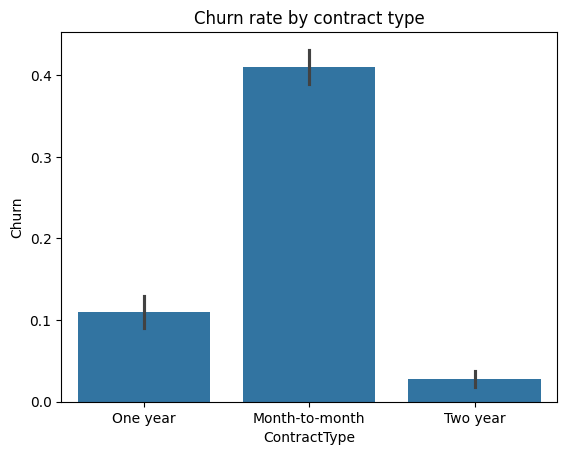

In [402]:
fig, ax = plt.subplots()
sns.barplot(data=churnconnect, x='ContractType', y='Churn', ax=ax)
ax.set_title("Churn rate by contract type")
plt.show()

The type of contract is associated with churn, month-to-month contract types have the highest rate by the largest margin.

I've seen a lot of customers with no internet service, I want to see if there is an association

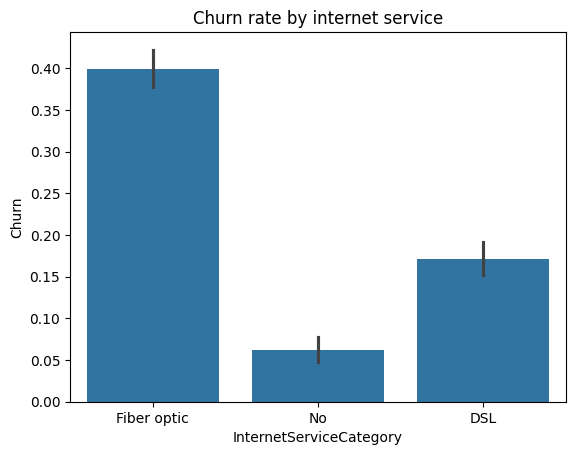

In [403]:
fig, ax = plt.subplots()
sns.barplot(data=churnconnect, x='InternetServiceCategory', y='Churn', ax=ax)
ax.set_title("Churn rate by internet service")
plt.show()

So actually, my initial thoughts were wrong. Fiber optic has the highest churn rate, i wonder if that has to do with the cost.

Lets look at the association, with the cost and churn rate.

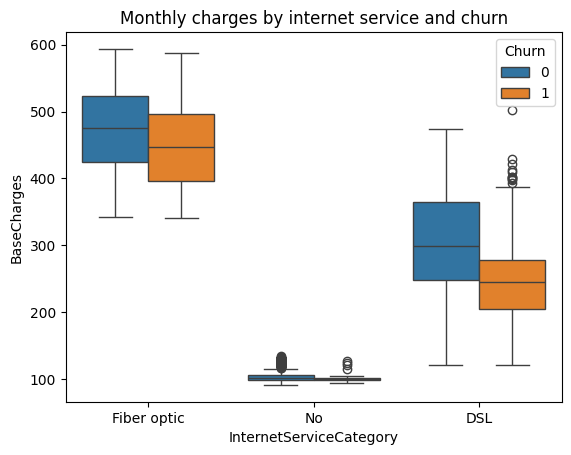

In [404]:
fig, ax = plt.subplots()
sns.boxplot(data=churnconnect, x='InternetServiceCategory', y='BaseCharges', hue='Churn', ax=ax)
ax.set_title("Monthly charges by internet service and churn")
plt.show()

Okay so from what I'm reading people who churned paid less

What all these are telling me is that the price does not drive churn. contract length tends to be more of a driver of churn.

It is time to move to modelling. I need to drop the unnecessary data.

In [352]:
X = churnconnect.drop(columns=['CustomerNo', 'DOE', 'DOC', 'Churn'],axis=1)
y = churnconnect['Churn']

Need to do the test data too

In [353]:
test_cn = testconnect['CustomerNo']
X_test = testconnect.drop(columns=['CustomerNo','DOE','DOC',],axis=1)

Tried to do churn in both the x and y test, turns out churn is not apart of that, which makes sense. Building the data and getting it ready for modelling

In [354]:
X.info()
X_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4238 entries, 0 to 4237
Data columns (total 22 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   DeviceProtection         4238 non-null   object 
 1   HasPhoneService          4238 non-null   object 
 2   InternetServiceCategory  4238 non-null   object 
 3   MultipleLines            4238 non-null   object 
 4   OnlineBackup             4238 non-null   object 
 5   OnlineSecurity           4238 non-null   object 
 6   StreamingMovies          4238 non-null   object 
 7   StreamingTelevision      4238 non-null   object 
 8   TechnicalSupport         4238 non-null   object 
 9   Country                  4238 non-null   object 
 10  State                    4238 non-null   object 
 11  Retired                  4238 non-null   int64  
 12  HasPartner               4238 non-null   int64  
 13  HasDependents            4238 non-null   object 
 14  Education               

In [355]:
X_numerical = X.select_dtypes(include=['int64','float64'])
X_test_numerical = X_test.select_dtypes(include=['int64','float64'])

Grabbing the numerical types, will grab the category types next

In [356]:
X_categorical = X.select_dtypes('object')
X_test_categorical = X_test.select_dtypes('object')

Categorical is grabbed

In [357]:
from sklearn.preprocessing import OneHotEncoder

In [358]:
onehot_encoder = OneHotEncoder(handle_unknown='ignore')
X_categorical_onehot = onehot_encoder.fit_transform(X_categorical)

In [359]:
onehot_encoder.categories_

[array(['No', 'No internet service', 'Yes'], dtype=object),
 array(['No', 'Yes'], dtype=object),
 array(['DSL', 'Fiber optic', 'No'], dtype=object),
 array(['No', 'No phone service', 'Yes'], dtype=object),
 array(['No', 'No internet service', 'Yes'], dtype=object),
 array(['No', 'No internet service', 'Yes'], dtype=object),
 array(['No', 'No internet service', 'Yes'], dtype=object),
 array(['No', 'No internet service', 'Yes'], dtype=object),
 array(['No', 'No internet service', 'Yes'], dtype=object),
 array(['?', 'India'], dtype=object),
 array(['?', 'Maharashtra'], dtype=object),
 array(['No', 'Yes'], dtype=object),
 array(['Graduation', 'Highschool or below', 'Masters', 'Other',
        'ProfessionalQualification'], dtype=object),
 array(['Female', 'Male'], dtype=object),
 array(['No', 'Yes'], dtype=object),
 array(['Month-to-month', 'One year', 'Two year'], dtype=object),
 array(['Bank transfer (automatic)', 'Credit card (automatic)',
        'Electronic check', 'Mailed check'], dty

Everything looks good, will be moving onto converting to an array.

In [360]:
column_names = onehot_encoder.get_feature_names_out()

In [361]:
X_categorical_onehot = X_categorical_onehot.toarray()
X_categorical_onehot = pd.DataFrame(X_categorical_onehot, columns=column_names)
X_categorical_onehot.head()

,DeviceProtection_No,DeviceProtection_No internet service,DeviceProtection_Yes,HasPhoneService_No,HasPhoneService_Yes,InternetServiceCategory_DSL,InternetServiceCategory_Fiber optic,InternetServiceCategory_No,MultipleLines_No,MultipleLines_No phone service,...,Gender_Male,ElectronicBilling_No,ElectronicBilling_Yes,ContractType_Month-to-month,ContractType_One year,ContractType_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,...,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
1,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,...,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
2,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
3,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,...,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
4,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,...,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0


In [362]:
X_test_categorical_onehot = onehot_encoder.transform(X_test_categorical)
X_test_categorical_onehot = X_test_categorical_onehot.toarray()
X_test_categorical_onehot = pd.DataFrame(X_test_categorical_onehot, columns=column_names)
X_test_categorical_onehot.head()

,DeviceProtection_No,DeviceProtection_No internet service,DeviceProtection_Yes,HasPhoneService_No,HasPhoneService_Yes,InternetServiceCategory_DSL,InternetServiceCategory_Fiber optic,InternetServiceCategory_No,MultipleLines_No,MultipleLines_No phone service,...,Gender_Male,ElectronicBilling_No,ElectronicBilling_Yes,ContractType_Month-to-month,ContractType_One year,ContractType_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,...,1.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
1,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,...,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
2,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
3,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,...,1.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
4,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0


In [363]:
X_categorical_onehot.info()
X_test_categorical_onehot.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4238 entries, 0 to 4237
Data columns (total 48 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   DeviceProtection_No                      4238 non-null   float64
 1   DeviceProtection_No internet service     4238 non-null   float64
 2   DeviceProtection_Yes                     4238 non-null   float64
 3   HasPhoneService_No                       4238 non-null   float64
 4   HasPhoneService_Yes                      4238 non-null   float64
 5   InternetServiceCategory_DSL              4238 non-null   float64
 6   InternetServiceCategory_Fiber optic      4238 non-null   float64
 7   InternetServiceCategory_No               4238 non-null   float64
 8   MultipleLines_No                         4238 non-null   float64
 9   MultipleLines_No phone service           4238 non-null   float64
 10  MultipleLines_Yes                        4238 no

In [364]:
X_train_encoded = pd.concat([X_numerical, X_categorical_onehot], axis=1)
X_train_encoded.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4238 entries, 0 to 4237
Data columns (total 53 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   Retired                                  4238 non-null   int64  
 1   HasPartner                               4238 non-null   int64  
 2   BaseCharges                              4238 non-null   float64
 3   TotalCharges                             4238 non-null   float64
 4   Lengthmonths                             4238 non-null   float64
 5   DeviceProtection_No                      4238 non-null   float64
 6   DeviceProtection_No internet service     4238 non-null   float64
 7   DeviceProtection_Yes                     4238 non-null   float64
 8   HasPhoneService_No                       4238 non-null   float64
 9   HasPhoneService_Yes                      4238 non-null   float64
 10  InternetServiceCategory_DSL              4238 no

In [365]:
X_test_encoded = pd.concat([X_test_numerical, X_test_categorical_onehot], axis=1)
X_test_encoded.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1060 entries, 0 to 1059
Data columns (total 53 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   Retired                                  1060 non-null   int64  
 1   HasPartner                               1060 non-null   int64  
 2   BaseCharges                              1060 non-null   float64
 3   TotalCharges                             1060 non-null   float64
 4   Lengthmonths                             1060 non-null   float64
 5   DeviceProtection_No                      1060 non-null   float64
 6   DeviceProtection_No internet service     1060 non-null   float64
 7   DeviceProtection_Yes                     1060 non-null   float64
 8   HasPhoneService_No                       1060 non-null   float64
 9   HasPhoneService_Yes                      1060 non-null   float64
 10  InternetServiceCategory_DSL              1060 no

Everything can be read by the model now. I dropped the metrics that won't matter like date and customer number. Then I prepped it for being read by the model.

In [366]:
from sklearn.tree import DecisionTreeClassifier

In [367]:
tree_clf = DecisionTreeClassifier(criterion='entropy', max_depth=3)
tree_clf.fit(X_train_encoded, y)

DecisionTreeClassifier(criterion='entropy', max_depth=3)

In [368]:
y_hat = tree_clf.predict(X_test_encoded)
y_hat = y_hat.astype(int)
y_hat

array([1, 0, 0, ..., 1, 0, 0], shape=(1060,))

In [369]:
churn_finalsubmissiondt = pd.DataFrame({'CustomerNo': test_cn,'Churn': y_hat,})
churn_finalsubmissiondt.head()

,CustomerNo,Churn
0,1203,1
1,1204,0
2,1208,0
3,1220,0
4,1221,0


Using the decision tree method in class this is what I got. Will save to csv and turn it into kaggle.

Forgot to connect my google drive

In [370]:
import os
from google.colab import drive

In [371]:
drive.mount('/content/drive')

mydrivedir = '/content/drive/My Drive/Colab Notebooks/output/'
os.makedirs(mydrivedir, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [372]:
churn_finalsubmissiondt.to_csv(f'{mydrivedir}/churn_tree_submit.csv', index=False)

I am now doing the linear regression

In [373]:
from sklearn.linear_model import LinearRegression

In [374]:
lin_reg = LinearRegression()
lin_reg.fit(X_train_encoded, y)

LinearRegression()

In [375]:
from sklearn.metrics import root_mean_squared_error

In [376]:
lin_reg.score(X_train_encoded, y)

0.31261332114992535

In [377]:
y_pred_lin = lin_reg.predict(X_train_encoded)

rmse = root_mean_squared_error(y, y_pred_lin)
print(rmse)

0.35781175746072064


Since we are relying on 0 and 1, rmse does not matter as much or I guess i should say is a little more difficult to interpret. But I can still use it to compare with the polynomial model I will do after.

In [378]:
y_hat_lin = lin_reg.predict(X_test_encoded)
y_hat_lin = (y_hat_lin >= 0.5).astype(int)

Needed to do >= 0.5 because it is using 0 and 1, so if I round up and down then it should be more accurate.

In [379]:
churn_finalsubmissionlr = pd.DataFrame({'CustomerNo': test_cn,'Churn': y_hat_lin,})
churn_finalsubmissionlr.head()

,CustomerNo,Churn
0,1203,0
1,1204,0
2,1208,0
3,1220,0
4,1221,0


In [380]:
churn_finalsubmissionlr.to_csv(f'{mydrivedir}/churn_linear_submit.csv', index=False)

Went up a few points with this new model. Will do polynomial now.

In [381]:
from sklearn.preprocessing import PolynomialFeatures

In [382]:
poly_features_2 = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly = poly_features_2.fit_transform(X_train_encoded)
X_test_poly = poly_features_2.transform(X_test_encoded)

In [383]:
poly_reg = LinearRegression()
poly_reg.fit(X_train_poly, y)
print(poly_reg.score(X_train_poly, y))

y_hat_poly = (poly_reg.predict(X_test_poly) >= 0.5).astype(int)

0.3970853654580807


Same deal as before need it to be >= 0.5

In [384]:
poly_reg = LinearRegression()
poly_reg.fit(X_train_poly, y)

LinearRegression()

In [385]:
y_pred_poly = poly_reg.predict(X_train_poly)
print(root_mean_squared_error(y, y_pred_poly))

0.3351058150452991


Lower than the lin regression, it fits better.

In [386]:
churn_finalsubmissionpoly = pd.DataFrame({'CustomerNo': test_cn,'Churn': y_hat_poly,})
churn_finalsubmissionpoly.head()

,CustomerNo,Churn
0,1203,0
1,1204,0
2,1208,0
3,1220,0
4,1221,0


In [387]:
churn_finalsubmissionpoly.to_csv(f'{mydrivedir}/churn_poly_submit.csv', index=False)

Trying a new decision tree depth of 5, changing it up above to see.

In [388]:
tree_clf2 = DecisionTreeClassifier(criterion='entropy', max_depth=5)
tree_clf2.fit(X_train_encoded, y)

DecisionTreeClassifier(criterion='entropy', max_depth=5)

In [389]:
y_hat_tree2 = tree_clf2.predict(X_test_encoded)
y_hat_tree2 = y_hat_tree2.astype(int)

In [390]:
churn_finalsubmissiondt2 = pd.DataFrame({'CustomerNo': test_cn,'Churn': y_hat_tree2,})
churn_finalsubmissiondt.head()

,CustomerNo,Churn
0,1203,1
1,1204,0
2,1208,0
3,1220,0
4,1221,0


In [391]:
churn_finalsubmissiondt2.to_csv(f'{mydrivedir}/churn_tree_depth5_submit.csv', index=False)

Okay, So, it is now clear that my first linear regression model was the better choice, the polynomial had a better fit but it over fit, which was made clear by the lower kaggle score. I will now be using the first linear regression model and messing with the threshold for churning.

I will start with 0.45. 0.5 felt like the right thing to do because it was right inbetween 0 and 1.

In [392]:
y_hat_lin2 = lin_reg.predict(X_test_encoded)
y_hat_lin2 = (y_hat_lin2 >= 0.45).astype(int)

In [393]:
churn_finalsubmissionlr2 = pd.DataFrame({'CustomerNo': test_cn,'Churn': y_hat_lin2,})
churn_finalsubmissionlr2.head()

,CustomerNo,Churn
0,1203,1
1,1204,0
2,1208,0
3,1220,0
4,1221,0


In [394]:
churn_finalsubmissionlr2.to_csv(f'{mydrivedir}/churn_linear_submit045.csv', index=False)

Slighty worse score, I will now do 0.55, I want to see which tightening up the restrictions for churn does.

In [395]:
print(lin_reg.intercept_)

-0.046484823057161284


In [397]:
y_hat_lin3 = lin_reg.predict(X_test_encoded)
y_hat_lin3 = (y_hat_lin3 >= 0.55).astype(int)
churn_finalsubmissionlr3 = pd.DataFrame({'CustomerNo': test_cn,'Churn': y_hat_lin3,})
churn_finalsubmissionlr3.head()

,CustomerNo,Churn
0,1203,0
1,1204,0
2,1208,0
3,1220,0
4,1221,0


In [398]:
churn_finalsubmissionlr3.to_csv(f'{mydrivedir}/churn_linear_submit055.csv', index=False)

same score as 0.45, I am going to raise the threshold one more time, and then explore other possibilities.

In [399]:
y_hat_lin4 = lin_reg.predict(X_test_encoded)
y_hat_lin4 = (y_hat_lin4 >= 0.60).astype(int)
churn_finalsubmissionlr4 = pd.DataFrame({'CustomerNo': test_cn,'Churn': y_hat_lin4,})
churn_finalsubmissionlr4.head()

,CustomerNo,Churn
0,1203,0
1,1204,0
2,1208,0
3,1220,0
4,1221,0


In [400]:
churn_finalsubmissionlr4.to_csv(f'{mydrivedir}/churn_linear_submit060.csv', index=False)

Even worse score, so I will stick with 0.5 and my original linear regression model.

I chose these three different models because I wanted to give each a try (Decision Tree, Linear Regression, Polynomial). The Linear Regression model was the best at predicting the churn rate. The polynomial while seemingly a better fit had a worse score. And the decision tree had the worst score. Hence, I chose the Original Linear Regression.